# 05 — Backtest and scenarios

**What this notebook shows.** Whether operating the reservoir on water values reproduces how Swedish hydro was actually run in 2015–2025, and what the model says about two questions: how much the Swedish water value moves with the continental price, and how a dry and a wet year play out from the same starting point.

All numbers are computed by `watervalues.simulate` from `data/processed/weekly_se.csv`. This is the same code that `uv run watervalues simulate` runs to write the backtest, its metrics, the scenarios, the checks and the report to `outputs/`. It solves the water values once per year, so it takes a little while.

In [1]:
from watervalues import plots
from watervalues.config import PROJECT_ROOT, load_config
from watervalues.data.build import load_weekly
from watervalues.sdp import capacity_gwh
from watervalues.simulate import run_simulations

cfg = load_config()
weekly = load_weekly(PROJECT_ROOT / cfg.data.weekly_csv)
result = run_simulations(cfg, weekly)
report = "\n".join(result.report)
capacity = capacity_gwh(cfg, weekly)
plots.use_style()
print(report[: report.index("Metrics per year")].strip())

Backtest: each ISO year simulated from its observed starting storage with its observed inflow, residual demand and German price. Its water values use the same residual demand and German price (so the only uncertainty is hydrological), a price curve fitted without the year and inflow scenarios without the year
  release grid 10 GWh; weeks with a filled residual demand, German price or inflow (left out of the price metrics): 2015-W01, 2015-W50, 2021-W50, 2022-W06
  a folded week 52 (with ISO week 53) is left out of the storage error


## Method

Week by week, the release is chosen on a grid of 10 GWh steps to minimise this week's cost plus the discounted value of the water left, $C_t(D_t - R) + c^{sp} Sp + \delta\, V_{t+1}(S')$. The value $V_{t+1}$ is interpolated between storage points, and water is spilled only when the reservoir would overflow. The simulated price is $p_t = a_t + b_t (D_t - R_t)$.

Each year of the backtest:
- starts from the storage actually observed at the start of the year;
- uses the inflow, residual demand and German price actually observed that week;
- has its water values solved again with that year's residual demand and German price. The model therefore knows both in advance, and its only uncertainty is hydrological, as intended.

Two precautions keep the test out of sample. The price curve is refitted without the year being tested, and that year is also removed from the inflow scenarios. The minimum release and the largest storage still come from all eleven years, an effect that was checked to be negligible.

The price error is split in two:
- **the curve error**: the year's price curve at the net import actually observed, minus the observed price, which is what the price model misses on its own;
- **the operating effect**: the simulated price minus that curve price, which is the price effect of operating the reservoir differently from reality.

## Storage: simulated and observed

Text(0.01, 0.98, 'Backtest: simulated and observed storage')

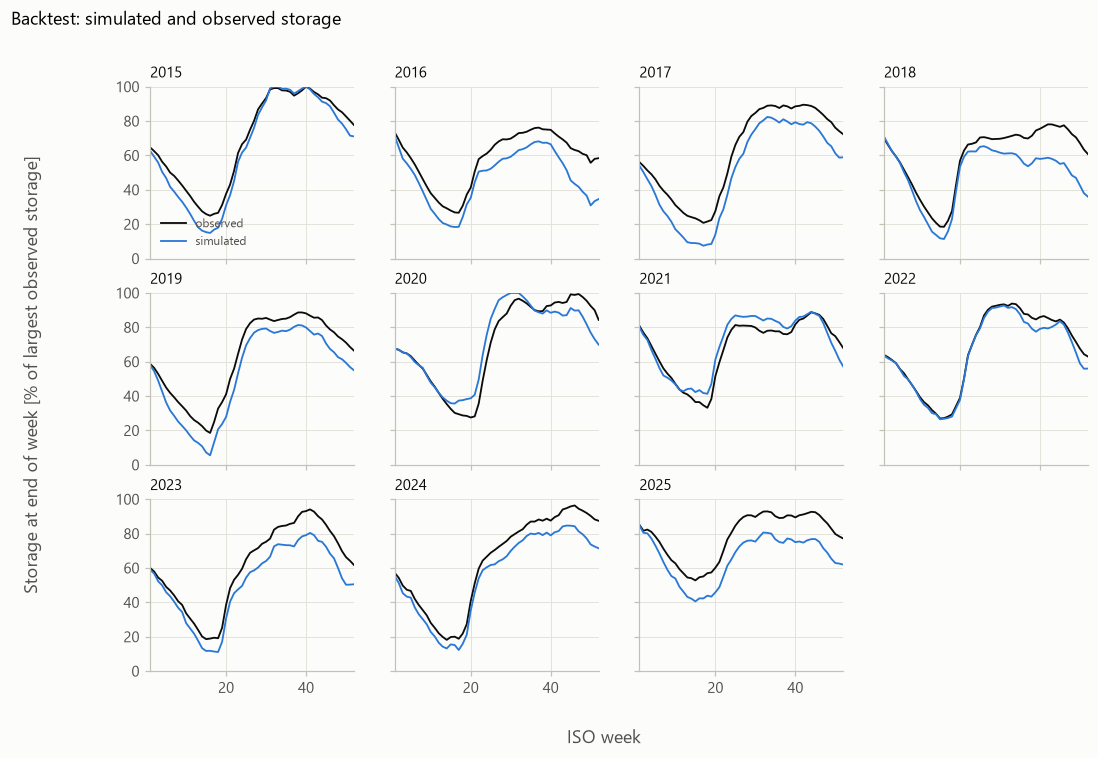

In [2]:
fig = plots.backtest_storage(result.backtest, capacity)
fig.suptitle("Backtest: simulated and observed storage", x=0.01, ha="left")

The simulation follows the seasonal shape of every year: the winter drawdown, the flood and the refill. It tracks the observed level closely in 2015, 2021 and 2022. In most other years it runs below the observed level, and the gap widens through the summer and autumn. The model releases more water than the producers did. In 2020, the wettest year, it fills the reservoir to the largest storage observed and spills; that level is below the reference capacity of Swedish reservoirs.

## Price: simulated and observed

Text(0.0, 1.0, 'Backtest: simulated and observed weekly price')

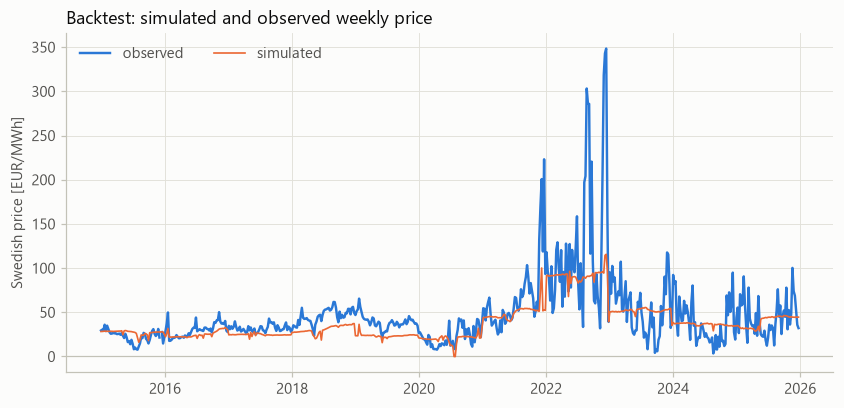

In [3]:
ax = plots.backtest_prices(result.backtest)
ax.set_title("Backtest: simulated and observed weekly price")

The simulated price follows the large moves between years, including the jump of 2021–2022, because the German price carries the level. It is far smoother within a year, because in the model the price follows the water value, which moves slowly along the storage path. The real weekly price also moves with wind, temperature and the Nordic hydrological balance, which the model holds fixed or leaves out.

## Metrics per year

In [4]:
result.metrics.round(2)

,price_corr,price_mae_eur_mwh,price_bias_eur_mwh,curve_bias_eur_mwh,operating_bias_eur_mwh,storage_rmse_pct,spill_gwh,observed_price_mean_eur_mwh,simulated_price_mean_eur_mwh,price_corr_within_year,price_corr_annual_means
iso_year,,,,,,,,,,,
2015,0.49,5.55,4.30,5.59,-1.30,6.25,1.71,22.60,26.90,NaN,NaN
2016,0.76,5.91,-5.00,-0.35,-4.65,12.10,0.00,29.95,24.95,NaN,NaN
2017,-0.04,7.24,-7.22,-3.19,-4.03,11.57,0.00,31.89,24.67,NaN,NaN
2018,0.65,14.82,-14.82,-7.90,-6.93,12.93,0.00,45.43,30.61,NaN,NaN
2019,0.76,15.63,-15.63,-12.41,-3.22,9.89,0.00,39.17,23.53,NaN,NaN
2020,0.44,8.09,-2.05,2.56,-4.61,8.06,656.32,21.77,19.73,NaN,NaN
2021,0.74,20.56,-15.90,-3.69,-12.21,5.48,0.00,65.73,49.82,NaN,NaN
2022,0.42,53.28,-35.69,-12.01,-23.68,3.39,0.00,126.44,90.75,NaN,NaN
2023,0.07,23.88,-1.73,7.60,-9.33,10.23,0.00,53.40,51.67,NaN,NaN


- **Correlation.** Pooled over all years, the weekly price correlation comes mostly from the level shifts between years. The correlation of the annual means is very high, while the correlation within years (prices less each year's mean) is much weaker.
- **The bias, and how it splits.** Over all years the simulated price is too low, and almost all of that is the operating effect: releasing more water than reality lowers the price. The curve error is small on average but large in single years. It is negative in 2018, 2019 and 2022, where the curve underprices even at the observed net import, and positive from 2023.
- **Storage.** The error is smallest in 2021–2022 and 2015, and largest where the simulated reservoir ends the year far below the observed one.

## Why the backtest misses where it does

The discrepancies are reported as they are; no parameter was tuned to reduce them. The model releases more water than producers did, with the demand and the German price known in advance. These are plausible causes, none of them tested here:

1. **Risk neutrality.** The model minimises expected cost, while producers also guard against the costly tail of a dry year by holding more water.
2. **Independent inflows.** The scenarios treat each week's inflow as independent, so the model underestimates the chance of a run of dry weeks, which is the risk that makes holding water pay.
3. **One national reservoir and price.** The model has no Norway, no zones and no transmission limits. The Nordic hydrological balance and the split of the northern from the southern zones from 2021 are outside it.
4. **Operating constraints left out.** Water rights, minimum flows per river and the producers' own hedging are not represented.

The backtest also flatters the model in one way: it knows the year's demand and German price in advance.

## Checks of the water values behind the simulations

In [5]:
print(report[report.index("Checks of the water values") : report.index("Scenario: German")].strip())
lowest = 100 * result.backtest["storage_end_gwh"].min() / capacity
print(f"\nLowest simulated storage in the backtest: {lowest:.1f}% of the largest storage observed")

Checks of the water values behind every simulation (converged; water values non-increasing in storage within the grid resolution, see watervalues solve)
                               converged  cycles  rising_cells  max_rise_eur_mwh  resolution_eur_mwh  max_rise_week  max_rise_filling_pct  rising_max_filling_pct  min_water_value_eur_mwh
solution                                                                                                                                                                                  
backtest 2015                        1.0     7.0           0.0              1.24                1.32           52.0                   0.5                     NaN                     0.18
backtest 2016                        1.0     6.0           1.0              1.39                1.19           52.0                   0.5                     0.5                     0.04
backtest 2017                        1.0     6.0          10.0              2.40                1.0

Every water value problem converges. In several backtest years the water values rise with storage beyond the grid resolution, always in the first percent or so of storage. That is the kink of the minimum-release rule at a near-empty reservoir, where all the water must be released. The simulated reservoir never gets that low, so the affected water values are not used by any decision shown here. The base case and the price scenarios pass the check.

## Scenario: the continental price level

Scenario: German price profile scaled to each annual mean; water value at the mean observed storage of each week [EUR/MWh]
                        water_value_mean_eur_mwh  water_value_min_eur_mwh  water_value_max_eur_mwh  price_mean_eur_mwh
de_price_level_eur_mwh                                                                                                
50.0                                        31.4                     29.9                     32.4                53.6
80.0                                        48.3                     46.3                     49.8                83.8
120.0                                       71.0                     68.2                     73.1               124.1
  slope of the mean water value: 0.57 EUR/MWh per EUR/MWh of German price


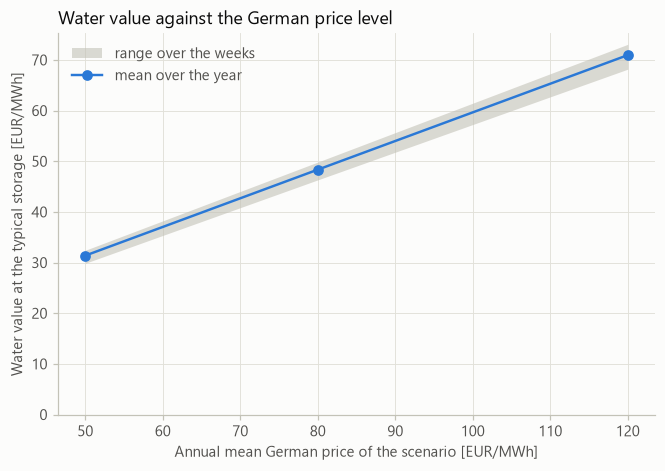

In [6]:
ax = plots.de_price_scenario(result.de_price)
ax.set_title("Water value against the German price level")
print(report[report.index("Scenario: German") : report.index("Scenario: driest")].strip())

The German price profile is scaled to several annual means and the water values are solved again. The water value along the typical storage path moves almost in a straight line with the continental price. Each EUR/MWh on the continent moves the Swedish water value by a little more than half a EUR/MWh.

Two effects of the price curve set this pass-through. The intercept follows the German price nearly one for one, while the proportional slope makes the export discount larger at higher prices. For a country that exports in most weeks, the answer to "how much does the Swedish water value move with the continent?" is therefore well below one for one.

## Scenario: the driest and the wettest year

Scenario: driest against wettest inflow year from the same initial storage
  dry (2016): inflow 55,436 GWh, release 66,835 GWh, spill 0 GWh; storage 5,187 to 19,959 GWh, ending at 9,963; price mean 51.9 EUR/MWh (weeks 44.9 to 69.5)
  wet (2020): inflow 78,868 GWh, release 74,715 GWh, spill 1 GWh; storage 8,549 to 30,694 GWh, ending at 25,514; price mean 42.0 EUR/MWh (weeks 17.1 to 49.1)


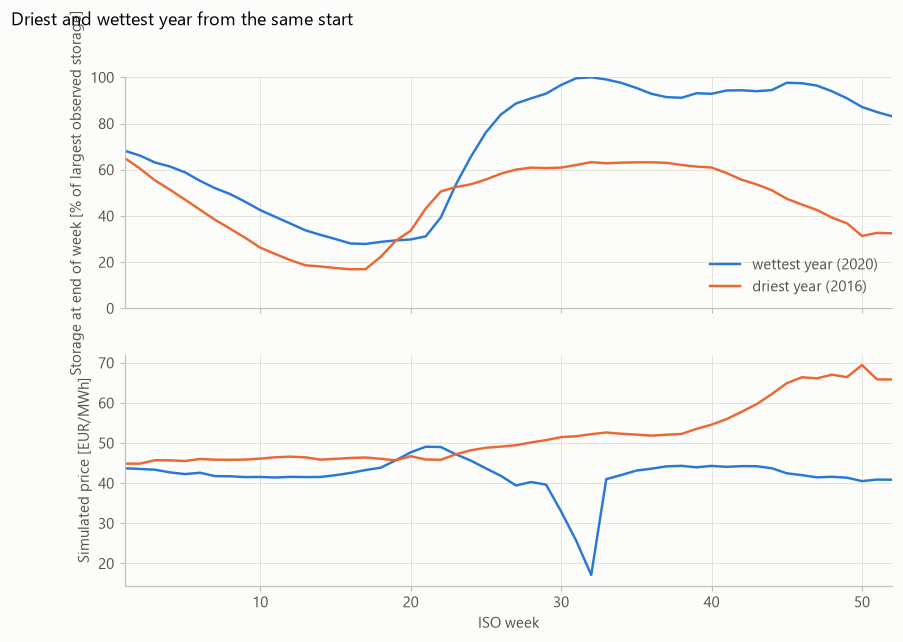

In [7]:
fig = plots.dry_and_wet(result.dry_wet, capacity)
fig.suptitle("Driest and wettest year from the same start", x=0.01, ha="left")
print(report[report.index("Scenario: driest") :].strip())

Both years start from the same storage, with the same demand and German price; only the inflow differs.

- **The wet year** fills the reservoir in the flood. When it is full, water has to be released or spilled, and the price falls sharply before recovering.
- **The dry year** never reaches more than a moderate level. It is drawn down through the autumn and ends the year low, and its price climbs steadily as the water value rises with scarcity.

Over the year the dry case is clearly more expensive, and it hands a much emptier reservoir to the next year.

## Limitations

- **Foresight in the backtest.** It knows each year's demand and German price in advance, so it shows the hydrological side of the model, not a real forecast.
- **The price curve.** It is linear in net import and estimated by OLS. Hydro responds to the price, so net import is not exogenous.
- **Risk neutrality.** The model minimises expected cost.
- **One national reservoir and price.** Each backtest year has ten independent inflow scenarios and each scenario run eleven, as in notebook 04.